<a href="https://colab.research.google.com/github/aureamc/A04-clustering/blob/main/My_Version_notebook_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

In [22]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aurea McIntosh

**Date:** 10/12/26

In [23]:
# Your Phase 1 solution to the problem goes here.


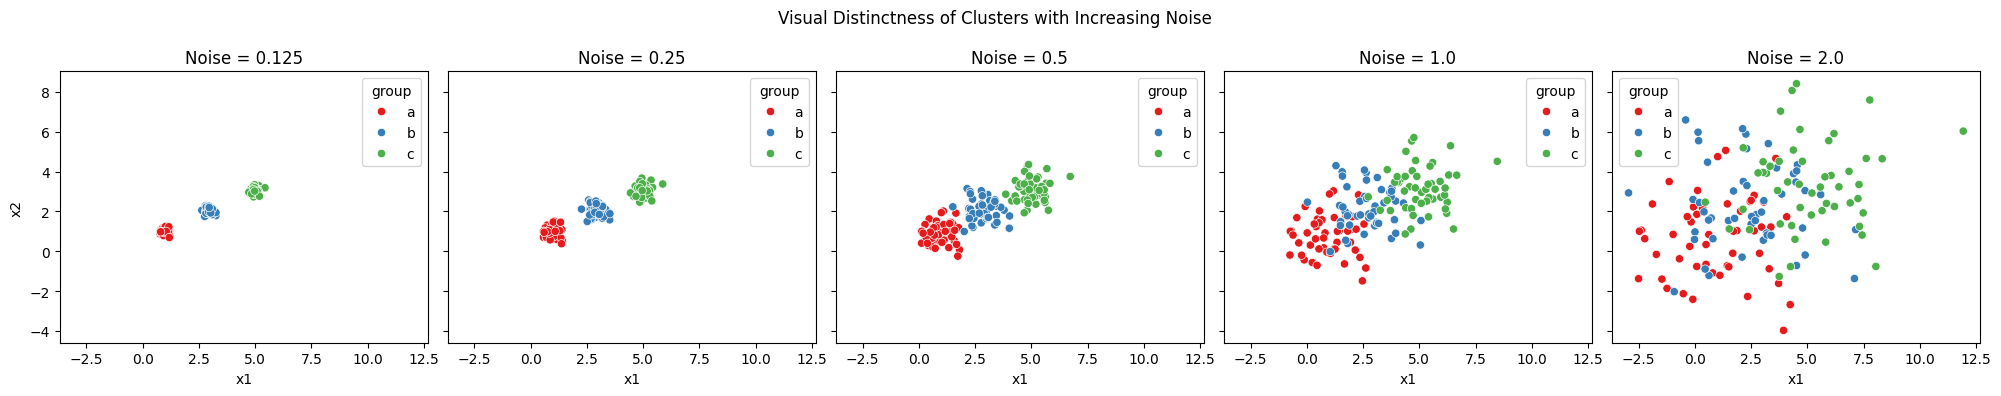

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

# --- Q1.1: create the datasets ---
def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

datasets = {
    '0.125': createData(0.125),
    '0.25': createData(0.25),
    '0.5': createData(0.5),
    '1.0': createData(1.0),
    '2.0': createData(2.0)
}

# --- Q1.2: scatter plots ---
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for i, (noise, df) in enumerate(datasets.items()):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=axes[i], palette='Set1')
    axes[i].set_title(f'Noise = {noise}')
plt.suptitle('Visual Distinctness of Clusters with Increasing Noise')
plt.tight_layout()
plt.show()

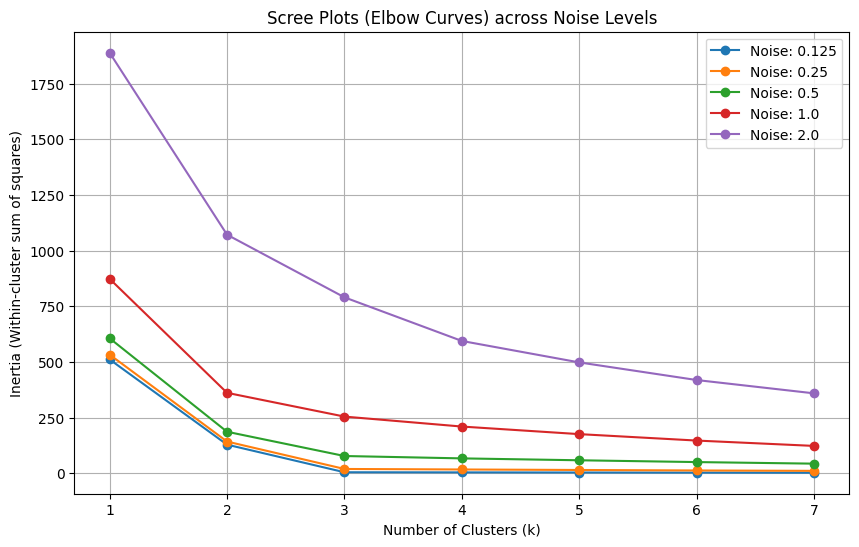

In [25]:
# --- Q1.3: scree plots ---
fig, ax = plt.subplots(figsize=(10, 6))

for noise, df in datasets.items():
    X = df[['x1', 'x2']]
    inertias = []
    ks = range(1, 8)
    for k in ks:
        kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)
    ax.plot(ks, inertias, marker='o', label=f'Noise: {noise}')

ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia (Within-cluster sum of squares)')
ax.set_title('Scree Plots (Elbow Curves) across Noise Levels')
ax.legend()
ax.grid(True)
plt.show()

### Q1 Explanations & Answers

- **Q1.2:** As noise increases from 0.125 to 2.0, the clusters begin to overlap. At 0.125, the clusters are seperated and  distinct. By 2.0, they merge completely into a single area of points, making seperate groups hard to see.
- **Q1.3:** With low noise (0.125, 0.25), there is a sharp, clear "elbow" at $k=3$. As noise increases, the elbow becomes  smoother and less distinct. At noise levels of 1.0 and 2.0, it is very difficult to select $k=3$ based on the curve alone.
- **Q1.4:** The "elbow" represents a point of diminishing returns. Adding more clusters up to $k=3$ reduces the cluster variance (inertia) because it captures distinct group centers. Past $k=3$, adding more clusters only splits existing ones, which cause smaller reductions in variance.

In [26]:
# --- Q2.1: Load and Clean SIPRI Database ---
file_path = '/content/SIPRI Military Expenditure Database.csv'
df_sipri = pd.read_csv(file_path)

# filter for 2020 and drop missing values
# checking columns first to find matching column names
print("Columns:", df_sipri.columns.tolist())


Columns: ['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP', 'Percent of Government Spending', 'Spending per Capita']


In [27]:
#check on the exact structure of the loaded dataframe
display(df_sipri.head(2))

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN


### Q2.1 - Load, Filter, and Clean the Data
Let's filter our SIPRI database to only keep the year 2020, and then remove any rows that have missing values (NaN) in the four columns we care about.

In [28]:
# 1: filter the rows to select only the year 2020
df_2020 = df_sipri[df_sipri['Year'] == 2020].copy()

# 2: 4 numerical columns we will use for the analysis
columns_to_keep = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of GDP',
    'Percent of Government Spending'
]

# 3: drop any rows that have missing values in these 4 columns
df_cleaned = df_2020.dropna(subset=columns_to_keep).copy()

# 4: print the number of countries left to make sure it matches
print("Number of countries remaining after cleaning:", len(df_cleaned))

# 5: verify the cleaned data
display(df_cleaned.head(5))

Number of countries remaining after cleaning: 148


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


### Q2.2 - Cluster on Absolute Spending and Spending per Capita
We will scale these two variables using Min-Max Normalization (scaling values between 0 and 1) so that the massive numbers in 'Spending' don't completely dominate the 'Spending per Capita' metric.

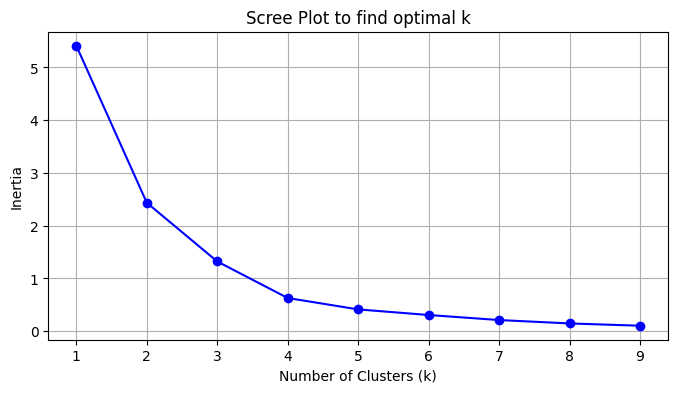

In [29]:
# 1. scale the two variables between 0 and 1
scaler = MinMaxScaler()
cols_to_scale = ['Spending (2020 USD)', 'Spending per Capita']
scaled_data_2 = scaler.fit_transform(df_cleaned[cols_to_scale])

# 2. make a simple scree plot to find the best k
inertias_2 = []
k_values = range(1, 10)

for k in k_values:
    # initialize
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    # fit the model
    model.fit(scaled_data_2)
    # keep track of the inertia
    inertias_2.append(model.inertia_)

# plot the scree curve
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias_2, marker='o', color='blue')
plt.title('Scree Plot to find optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

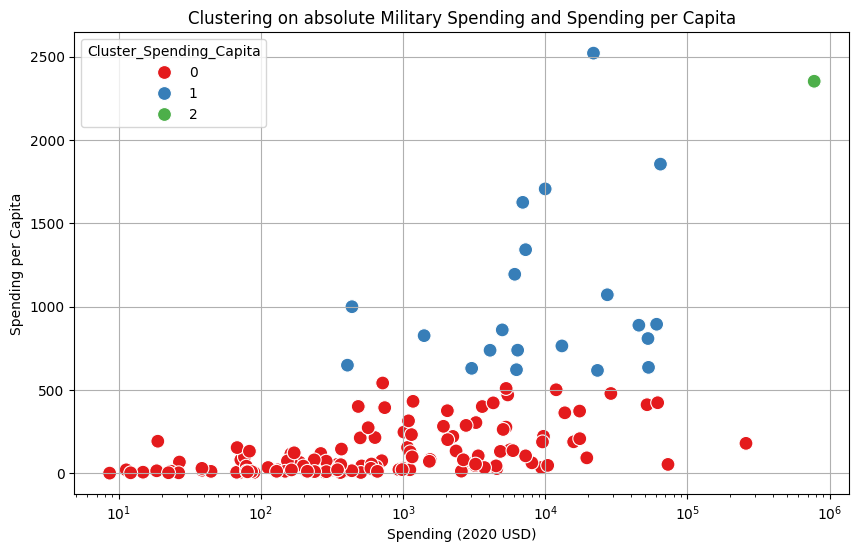

,Spending (2020 USD),Spending per Capita
Cluster_Spending_Capita,,
0,5943.346303,122.034996
1,19975.991473,1046.433509
2,778397.200000,2351.631858


In [30]:
# 3. choose k = 3 because that's where the elbow is most visible
optimal_k = 3
kmeans_model = KMeans(n_clusters=optimal_k, random_state=100, n_init=10)

# assign each country to a cluster
df_cleaned['Cluster_Spending_Capita'] = kmeans_model.fit_predict(scaled_data_2)

# 4. make a scatter plot of the clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_cleaned,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='Cluster_Spending_Capita',
    palette='Set1',
    s=100
)

# find and label the US
us_data = df_cleaned[df_cleaned['Country'] == 'United States']
if not us_data.empty:
    plt.text(
        us_data['Spending (2020 USD)'].values[0],
        us_data['Spending per Capita'].values[0],
        ' <-- United States',
        weight='bold',
        color='black'
    )

plt.title('Clustering on absolute Military Spending and Spending per Capita')
plt.xscale('log') # We use log scale because the US spends much more than others
plt.grid(True)
plt.show()

# 5. show stats for each cluster group
display(df_cleaned.groupby('Cluster_Spending_Capita')[cols_to_scale].mean())

### Q2.3 - Cluster on % of GDP and % of Government Spending
Now let's repeat the exact same process, but this time using the percentage indicators.

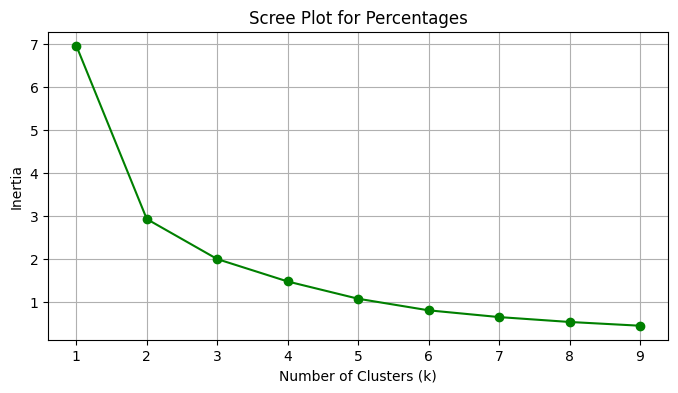

In [31]:
# 1. scale the percentage variables
cols_to_scale_pct = ['Percent of GDP', 'Percent of Government Spending']
scaled_data_3 = scaler.fit_transform(df_cleaned[cols_to_scale_pct])

# 2. run KMeans and make a scree Plot
inertias_3 = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(scaled_data_3)
    inertias_3.append(model.inertia_)

# plot the scree curve
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias_3, marker='o', color='green')
plt.title('Scree Plot for Percentages')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

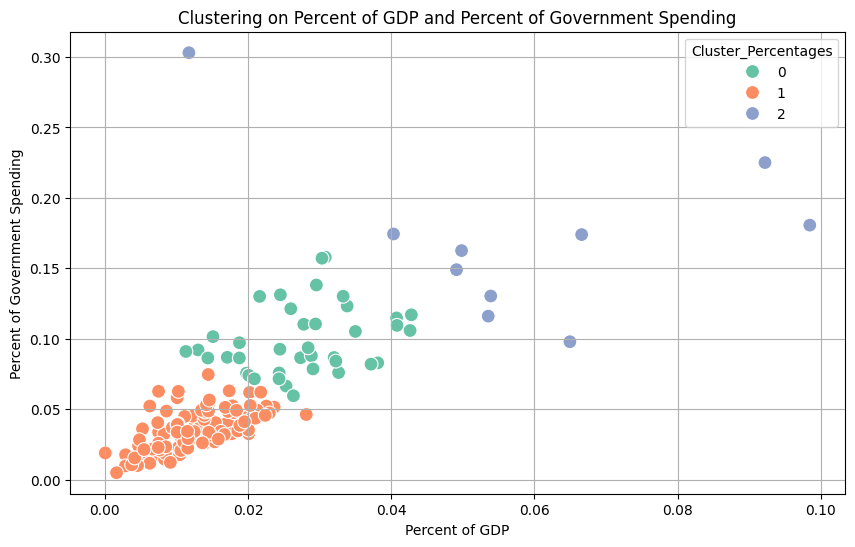

,Percent of GDP,Percent of Government Spending
Cluster_Percentages,,
0,0.027412,0.098683
1,0.012664,0.035777
2,0.058071,0.171289


In [32]:
# 3. fit KMeans with k = 3
kmeans_model_pct = KMeans(n_clusters=3, random_state=100, n_init=10)
df_cleaned['Cluster_Percentages'] = kmeans_model_pct.fit_predict(scaled_data_3)

# 4. create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_cleaned,
    x='Percent of GDP',
    y='Percent of Government Spending',
    hue='Cluster_Percentages',
    palette='Set2',
    s=100
)

# label the US
us_data = df_cleaned[df_cleaned['Country'] == 'United States']
if not us_data.empty:
    plt.text(
        us_data['Percent of GDP'].values[0],
        us_data['Percent of Government Spending'].values[0],
        ' <-- United States',
        weight='bold',
        color='black'
    )

plt.title('Clustering on Percent of GDP and Percent of Government Spending')
plt.grid(True)
plt.show()

# 5. display the average stats for each
display(df_cleaned.groupby('Cluster_Percentages')[cols_to_scale_pct].mean())

### Q2.4 & Q2.5 - Clustering on All Four Variables & Final Insights
Finally, we run the clustering algorithm on all four features together so we can analyze countries with a complete overview of their profile.

In [33]:
# 1. scale all four variables together
scaled_data_all = scaler.fit_transform(df_cleaned[columns_to_keep])

# 2. perform KMeans with k = 4
kmeans_all = KMeans(n_clusters=4, random_state=100, n_init=10)
df_cleaned['Cluster_All_Features'] = kmeans_all.fit_predict(scaled_data_all)

# 3. create a clean profile table showing the mean of each metric per cluster
profile_table = df_cleaned.groupby('Cluster_All_Features')[columns_to_keep].mean()
print("Average metrics for each cluster:")
display(profile_table)

Average metrics for each cluster:


,Spending (2020 USD),Spending per Capita,Percent of GDP,Percent of Government Spending
Cluster_All_Features,,,,
0,15330.618681,612.677541,0.016585,0.033280
1,9073.543709,215.920971,0.034105,0.123701
2,4513.543790,70.290644,0.012481,0.043199
3,147964.582042,1875.150751,0.062634,0.135351


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** Gemini

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [34]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]